# 2. Comparar modelos con tu dataset limpio
Entrada: V0.1/LICIT_depurando_sinNulos.feather. Se comparan regresión logística,
árbol de decisión, red neuronal MLP y Random Forest. No se utilizan CSV mensuales.

**Limitación:** el archivo no permite agrupar por licitación ni validar en el tiempo.
Separar vectores idénticos por grupos reduce una contaminación concreta, pero
distintas filas de una misma licitación todavía podrían estar en conjuntos diferentes.
No interpretes las métricas como una prueba de rendimiento en licitaciones futuras.

**Objetivo actual:** equilibrar precision y oportunidades detectadas.
Las secciones iniciales conservan como referencia la politica restrictiva del 10%.
Las secciones 2.6 y 2.7 comparan 30% y 50% y dejan el 30% como punto operativo
intermedio predeterminado. El notebook 03 carga ese punto operativo.


In [1]:
from pathlib import Path
import os
BASE = Path.cwd().resolve()
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists() and (BASE / "V0.2" / "02_Comparacion_de_Modelos.ipynb").exists():
    BASE = BASE / "V0.2"
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists():
    raise FileNotFoundError("Abre el proyecto desde la raíz o desde V0.2.")
os.chdir(BASE)
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
FUENTE = BASE.parent / "V0.1" / "LICIT_depurando_sinNulos.feather"
SALIDA = BASE / "resultados_dataset_limpio"
SALIDA.mkdir(exist_ok=True)
print("Dataset de entrada:", FUENTE)

Dataset de entrada: D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_sinNulos.feather


## 2.1. Datos, configuración y procedencia
Para controlar tiempo, cada modelo se ajusta con hasta 120.000 filas de TRAIN,
seleccionando grupos completos con semilla fija. Calibración, validación y test
conservan sus registros. MAX_FILAS_TRAIN=None usa todo TRAIN.
La configuración y las huellas de datos/código controlan la reutilización.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
    brier_score_loss, log_loss)
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
EXCLUIR = ["NumeroOferentes", "CantidadReclamos", "DuracionProceso"]
CODIGOS = ["CodigoUnidad", "CodigoProductoONU"]

# Funciones auxiliares incluidas aquí: no se requieren módulos .py del proyecto.
def catalogo(incluir_random_forest=False):
    """Mismos tres algoritmos del trabajo original, sin ofertas sintéticas."""
    modelos = {
        "Regresion_Logistica": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        "Arbol_Decision": DecisionTreeClassifier(max_depth=10, min_samples_leaf=50,
                                                class_weight="balanced", random_state=42),
        "Red_Neuronal_MLP": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=100,
                                          early_stopping=True, n_iter_no_change=8,
                                          random_state=42),
    }
    if incluir_random_forest:
        modelos["Random_Forest"] = RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=30,
            class_weight="balanced_subsample", random_state=42, n_jobs=2)
    return modelos

def metricas(y, p, umbral):
    pred = p >= umbral
    return {"F1": float(f1_score(y, pred, zero_division=0)),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "ROC_AUC": float(roc_auc_score(y, p)),
            "average_precision": float(average_precision_score(y, p)),
            "Brier": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, p)),
            "matriz_confusion_orden_0_1": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def umbral_f1(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    den = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], den, out=np.zeros_like(den), where=den > 0)
    return float(thresholds[int(np.argmax(f1))])

def umbral_precision(y, p, recall_minimo=0.10, min_alertas=200):
    """Maximiza precisión en validación con cobertura y soporte mínimos.

    En caso de empate elige mayor recall. No consulta etiquetas de test.
    min_alertas evita elegir un punto apoyado en muy pocas predicciones positivas.
    """
    if not 0 < recall_minimo <= 1 or min_alertas < 1:
        raise ValueError("Revisa recall_minimo (0,1] y min_alertas >= 1.")
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    if set(np.unique(y)) != {0, 1} or not np.isfinite(p).all():
        raise ValueError("Se necesitan ambas clases y probabilidades finitas.")
    precisiones, recalls, umbrales = precision_recall_curve(y, p)
    # Cada punto usa la regla p >= umbral, incluidos los empates de probabilidad.
    alertas = len(p) - np.searchsorted(np.sort(p), umbrales, side="left")
    validos = (recalls[:-1] >= recall_minimo) & (alertas >= min_alertas)
    indices = np.flatnonzero(validos)
    if not len(indices):
        raise ValueError("No hay umbral que cumpla cobertura y soporte mínimos.")
    orden = np.lexsort((recalls[:-1][indices], precisiones[:-1][indices]))
    idx = indices[orden[-1]]
    return {"umbral": float(umbrales[idx]), "precision_validacion": float(precisiones[idx]),
            "recall_validacion": float(recalls[idx]), "alertas_validacion": int(alertas[idx])}


In [3]:
def preparar_limpio(ruta):
    """Verifica el dataset del usuario; no repite su cadena de depuración."""
    df = pd.read_feather(ruta)
    requeridas = ["Seleccionada", "Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]
    faltan = sorted(set(requeridas) - set(df.columns))
    if faltan:
        raise ValueError(f"Faltan columnas en el Feather limpio: {faltan}")
    antes = len(df)
    valido = df.Seleccionada.isin([0, 1])
    valido &= df[["Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]].gt(0).all(axis=1)
    df = df.loc[valido].copy().reset_index(drop=True)
    y = df.pop("Seleccionada").astype("int8")
    X = df.drop(columns=EXCLUIR, errors="ignore")
    # Los montos ya están transformados por V0.1. No se reconvierten monedas.
    # No asumimos que el presupuesto global es un presupuesto por ítem.
    for columna in ["MontoEstimado", "Valor Total Ofertado", "Cantidad", "Cantidad Ofertada"]:
        if columna in X:
            X[columna] = np.log1p(X[columna].clip(lower=0))
    for columna in CODIGOS:
        if columna in X:
            X[columna] = X[columna].astype("string").fillna("sin_codigo").astype(str)
    numericas = X.select_dtypes(include="number").columns
    X[numericas] = X[numericas].replace([np.inf, -np.inf], np.nan)
    # La huella NO incluye el objetivo: vectores idénticos se mantienen juntos
    # aunque sus etiquetas sean diferentes. No representa una licitación real.
    grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
    auditoria = {"archivo": str(Path(ruta).resolve()), "filas_entrada": antes,
                 "filas_utilizadas": len(X), "filas_excluidas": antes-len(X),
                 "motivo_exclusion": "Objetivo inválido o monto/cantidad de oferta no positivo",
                 "predictores": X.columns.tolist(), "excluidas_por_disponibilidad": EXCLUIR,
                 "limitacion": "Sin identificador de licitación ni fechas exactas; no se verifica generalización temporal por licitación.",
                 "grupos": "Huella de predictores, no ID de licitación",
                 "transformacion": "log1p en montos y cantidades; códigos como categorías"}
    return X, y, grupos, auditoria

def dividir_grupos(indices, grupos, fraccion, semilla):
    splitter = GroupShuffleSplit(n_splits=1, test_size=fraccion, random_state=semilla)
    a, b = next(splitter.split(indices, groups=grupos[indices]))
    return indices[a], indices[b]

def separar_limpio(y, grupos):
    indices = np.arange(len(y))
    desarrollo, test = dividir_grupos(indices, grupos, .15, 42)
    desarrollo, validacion = dividir_grupos(desarrollo, grupos, .15/.85, 43)
    train, calibracion = dividir_grupos(desarrollo, grupos, .15/.70, 44)
    partes = dict(train=train, calibracion=calibracion, validacion=validacion, test=test)
    vistos = set()
    for nombre, idx in partes.items():
        actuales = set(grupos[idx])
        if vistos & actuales:
            raise AssertionError("Se compartieron predictores idénticos entre conjuntos.")
        vistos |= actuales
        if set(y.iloc[idx]) != {0, 1}:
            raise ValueError(f"{nombre} debe contener ambas clases.")
    return partes

In [4]:
import hashlib
MAX_FILAS_TRAIN = 120_000
REENTRENAR = False
RECALL_MINIMO = 0.10
MIN_ALERTAS_VALIDACION = 200
X, y, grupos, auditoria = preparar_limpio(FUENTE)
partes = separar_limpio(y, grupos)
with FUENTE.open("rb") as f:
    huella = hashlib.file_digest(f, "sha256").hexdigest()
config = {"dataset": huella, "codigo": hashlib.sha256("".join("".join(c["source"]) for c in json.loads((BASE/"02_Comparacion_de_Modelos.ipynb").read_text(encoding="utf-8"))["cells"] if c["cell_type"] == "code").encode("utf-8")).hexdigest(),
          "max_filas_train": MAX_FILAS_TRAIN, "objetivo": "precision",
          "recall_minimo": RECALL_MINIMO, "min_alertas": MIN_ALERTAS_VALIDACION}
control = SALIDA / "configuracion.json"
necesarios = ["modelo_dataset_limpio.joblib", "cv.json", "validacion.json", "probabilidades_test.npy", "prueba_registros.csv"]
hay = all((SALIDA / n).exists() for n in necesarios) and control.exists()
EJECUTAR = REENTRENAR or not hay or json.loads(control.read_text(encoding="utf-8")) != config
display(pd.DataFrame({k: {"filas": len(v), "seleccionadas_pct": y.iloc[v].mean()*100}
                      for k,v in partes.items()}).T)
print("Entrenar:", EJECUTAR)

# Conservamos métricas de la política anterior para mostrar el intercambio,
# sin utilizarlas para seleccionar el nuevo modelo o umbral.
RUTA_ANTERIOR = SALIDA / "modelo_dataset_limpio.joblib"
REFERENCIA_ANTERIOR = None
if RUTA_ANTERIOR.exists():
    informe_previo = joblib.load(RUTA_ANTERIOR)["informe"]
    REFERENCIA_ANTERIOR = informe_previo.get("referencia_anterior")
    if REFERENCIA_ANTERIOR is None and informe_previo.get("objetivo") != "precision":
        REFERENCIA_ANTERIOR = {"modelo": informe_previo["modelo"], "test": informe_previo["test"]}


,filas,seleccionadas_pct
train,1158990.0,17.017403
calibracion,315803.0,16.914659
validacion,315785.0,16.924490
test,315036.0,16.843472


Entrenar: False


## 2.2. Pipeline y muestra de entrenamiento
Se conservan las columnas one-hot existentes. Imputación, escala y categorías
de códigos se aprenden solamente en el subconjunto de ajuste. Los grupos se
crean sin usar Seleccionada: vectores iguales con objetivos diferentes quedan juntos.
La separación principal tiene aproximadamente 55/15/15/15 por grupos, sin estratificar;
se comprueba que cada conjunto contenga ambas clases y se muestran sus proporciones.

In [5]:
def pipeline_limpio(X, modelo):
    categorias = [c for c in CODIGOS if c in X]
    numeros = [c for c in X if c not in categorias]
    prep = ColumnTransformer([
        ("numeros", Pipeline([("imputar", SimpleImputer(strategy="median")),
                               ("escalar", StandardScaler())]), numeros),
        ("codigos", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                  max_categories=150), categorias),
    ])
    return Pipeline([("preprocesar", prep), ("modelo", modelo)])

def limitar_indices(indices, grupos, limite):
    if limite is None or len(indices) <= limite:
        return indices
    # Selección reproducible de grupos enteros, compartida por los algoritmos.
    tamanos = pd.Series(grupos[indices]).value_counts().sample(frac=1, random_state=42)
    elegidos, total = [], 0
    for grupo, cantidad in tamanos.items():
        if total + cantidad <= limite:
            elegidos.append(grupo)
            total += cantidad
    salida = indices[np.isin(grupos[indices], elegidos)]
    if not len(salida):
        raise ValueError("El límite de entrenamiento no admite ningún grupo completo.")
    return salida

def ajustar_limpio(X, y, grupos, fit, cal, modelo, limite):
    fit = limitar_indices(fit, grupos, limite)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        base = pipeline_limpio(X, modelo).fit(X.iloc[fit], y.iloc[fit])
    calibrado = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid")
    calibrado.fit(X.iloc[cal], y.iloc[cal])
    return calibrado, {"filas_ajuste": len(fit), "segundos": time.perf_counter()-inicio,
                        "advertencias": [str(a.message) for a in avisos]}

## 2.3. Validación cruzada de los cuatro algoritmos
Se usan tres folds de GroupKFold dentro de TRAIN. Cada fold reserva calibración
interna independiente. Esta CV es por vectores idénticos, no temporal ni por licitación.
F1 se mide con umbral 0,5 en CV; el umbral final se elegirá después en validación.
Logística y árbol usan pesos de clase; Random Forest pesos en sus muestras;
MLP usa sus ejemplos sin balanceo y parada temprana interna dentro de TRAIN.

In [6]:
def cv_limpio(X, y, grupos, train, limite=120_000):
    resultados = []
    cv = GroupKFold(n_splits=3, shuffle=True, random_state=42)
    for fold, (fit_local, val_local) in enumerate(cv.split(train, y.iloc[train], grupos[train]), start=1):
        fit, cal = dividir_grupos(train[fit_local], grupos, .2, 42)
        val = train[val_local]
        for nombre, modelo in catalogo(True).items():
            print(f"CV {fold}: {nombre}", flush=True)
            calibrado, detalle = ajustar_limpio(X, y, grupos, fit, cal, modelo, limite)
            p = calibrado.predict_proba(X.iloc[val])[:, 1]
            resultados.append({"modelo": nombre, "fold": fold, **metricas(y.iloc[val], p, .5), **detalle})
    return pd.DataFrame(resultados)

In [7]:
if EJECUTAR:
    cv = cv_limpio(X, y, grupos, partes["train"], MAX_FILAS_TRAIN)
    cv.to_json(SALIDA / "cv.json", orient="records", indent=2)
else:
    cv = pd.read_json(SALIDA / "cv.json")
metricas_comparar = ["precision", "recall", "F1", "ROC_AUC", "average_precision", "Brier"]
resumen = cv.groupby("modelo")[metricas_comparar].agg(["mean", "std"])
display(resumen.round(4))

precision          recall              F1         ROC_AUC  \
                         mean     std    mean     std    mean     std    mean   
modelo                                                                          
Arbol_Decision         0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.6245   
Random_Forest          0.7676  0.0447  0.0042  0.0016  0.0083  0.0032  0.6387   
Red_Neuronal_MLP       0.5141  0.0189  0.0293  0.0036  0.0554  0.0064  0.6475   
Regresion_Logistica    0.2589  0.0666  0.0005  0.0002  0.0009  0.0003  0.6261   

                            average_precision           Brier          
                        std              mean     std    mean     std  
modelo                                                                 
Arbol_Decision       0.0047            0.2495  0.0081  0.1371  0.0008  
Random_Forest        0.0027            0.2679  0.0057  0.1360  0.0007  
Red_Neuronal_MLP     0.0030            0.2783  0.0034  0.1355  0.0008  
Regresion_Logistica  0.0011            0.2520  0.0036  0.1370  0.0008

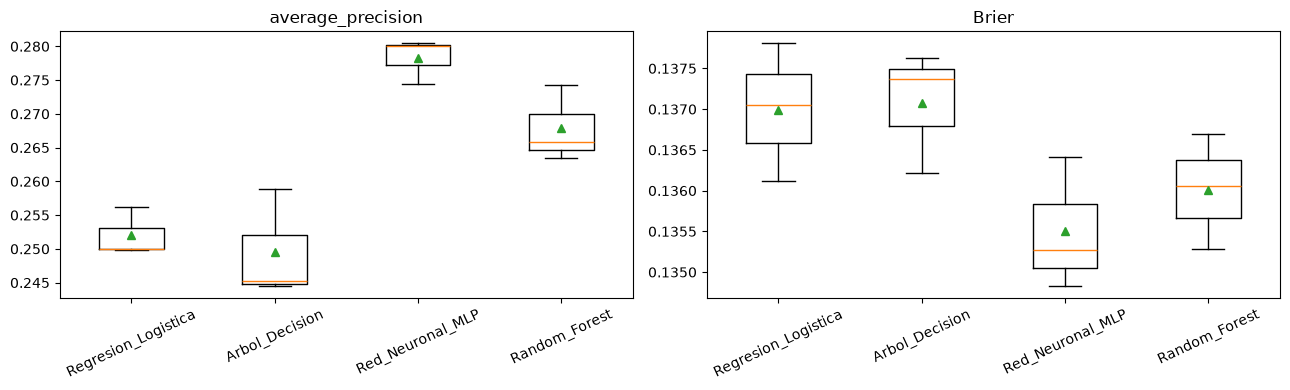

In [8]:
nombres = list(cv.modelo.unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica in zip(axes, ["average_precision", "Brier"]):
    ax.boxplot([cv.loc[cv.modelo.eq(n), metrica] for n in nombres], tick_labels=nombres, showmeans=True)
    ax.set_title(metrica)
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

## 2.4. Priorizar precisión en validación

Para cada algoritmo elegimos el umbral con mayor precisión, sujeto a detectar
al menos el 10% de los positivos de validación y emitir al menos 200 predicciones
positivas. En empate se prefiere mayor recall. Son parámetros configurables del paso 2.1.

Después elegimos el modelo por precisión en validación, con recall y Brier como
desempates. Se muestran también los resultados del umbral que maximiza F1 para
entender el intercambio. No garantizamos alcanzar una precisión concreta.
La cobertura mínima se exige en validación; podría no mantenerse en test o datos nuevos.


In [9]:
def validar_limpio(X, y, grupos, partes, limite=120_000,
                   recall_minimo=0.10, min_alertas=200):
    entrenados, resultados = {}, []
    for nombre, modelo in catalogo(True).items():
        print(f"Ajuste final: {nombre}", flush=True)
        calibrado, detalle = ajustar_limpio(X, y, grupos, partes["train"], partes["calibracion"], modelo, limite)
        val = partes["validacion"]
        p = calibrado.predict_proba(X.iloc[val])[:, 1]
        # Elegimos ambos puntos de operación exclusivamente con VALIDACIÓN.
        comparacion_f1 = metricas(y.iloc[val], p, umbral_f1(y.iloc[val], p))
        opt = umbral_precision(y.iloc[val], p, recall_minimo, min_alertas)
        umbral = opt["umbral"]
        resultados.append({"modelo": nombre, "umbral": umbral,
                           **metricas(y.iloc[val], p, umbral),
                           "alertas_validacion": opt["alertas_validacion"],
                           "precision_umbral_F1": comparacion_f1["precision"],
                           "recall_umbral_F1": comparacion_f1["recall"], **detalle})
        entrenados[nombre] = calibrado
    return entrenados, pd.DataFrame(resultados).sort_values(
        ["precision", "recall", "Brier"], ascending=[False, False, True]).reset_index(drop=True)


In [10]:
if EJECUTAR:
    entrenados, tabla = validar_limpio(X, y, grupos, partes, MAX_FILAS_TRAIN, RECALL_MINIMO, MIN_ALERTAS_VALIDACION)
    tabla.to_json(SALIDA / "validacion.json", orient="records", indent=2)
else:
    tabla = pd.read_json(SALIDA / "validacion.json")
display(tabla[["modelo", "umbral", *metricas_comparar, "alertas_validacion", "precision_umbral_F1", "recall_umbral_F1", "filas_ajuste", "segundos"]])
display(tabla[["modelo", "advertencias"]])

,modelo,umbral,precision,recall,F1,ROC_AUC,average_precision,Brier,alertas_validacion,precision_umbral_F1,recall_umbral_F1,filas_ajuste,segundos
0,Red_Neuronal_MLP,0.326651,0.379078,0.100009,0.158265,0.648675,0.273208,0.135200,14100,0.235686,0.624717,120000,14.279321
1,Random_Forest,0.305669,0.353135,0.100215,0.156124,0.635201,0.260800,0.135766,15167,0.224740,0.633287,120000,9.925500
2,Regresion_Logistica,0.267753,0.327078,0.121321,0.176992,0.624272,0.246758,0.136604,19824,0.215693,0.665731,120000,2.753371
3,Arbol_Decision,0.260311,0.287559,0.100421,0.148858,0.625153,0.241601,0.136657,18664,0.213380,0.721695,120000,3.644996


,modelo,advertencias
0,Red_Neuronal_MLP,[]
1,Random_Forest,[]
2,Regresion_Logistica,[]
3,Arbol_Decision,[]


## 2.5. Prueba del ganador
Solo se evalúa en test el candidato seleccionado. Se compara contra una probabilidad
constante basada en TRAIN, se guarda el modelo y se exportan diez registros de
ejemplo con su resultado real. El histórico de 2024 ya fue analizado previamente:
esto es una comparación exploratoria, no una nueva confirmación independiente.

In [11]:
def probar_limpio(X, y, partes, entrenados, tabla, auditoria, salida, referencia_anterior=None, recall_minimo=0.10, min_alertas=200):
    ganador = tabla.iloc[0]
    nombre, umbral = ganador["modelo"], float(ganador["umbral"])
    modelo = entrenados[nombre]
    test = partes["test"]
    p = modelo.predict_proba(X.iloc[test])[:, 1]
    dummy = DummyClassifier(strategy="prior").fit(X.iloc[partes["train"]], y.iloc[partes["train"]])
    referencia = dummy.predict_proba(X.iloc[test])[:, 1]
    observada, predicha = calibration_curve(y.iloc[test], p, n_bins=10, strategy="quantile")
    informe = {"modelo": nombre, "umbral": umbral, "test": metricas(y.iloc[test], p, umbral),
               "referencia": metricas(y.iloc[test], referencia, .5), "auditoria": auditoria,
               "calibracion": {"predicha": predicha.tolist(), "observada": observada.tolist()},
               "particiones": {k: {"filas": len(v), "tasa_seleccion": float(y.iloc[v].mean())} for k, v in partes.items()},
               "objetivo": "precision", "recall_minimo_validacion": recall_minimo,
               "min_alertas_validacion": min_alertas, "referencia_anterior": referencia_anterior,
               "positivos_predichos_test": int((p >= umbral).sum()),
               "cobertura_test": float((p >= umbral).mean()),
               "nota": "Evaluación exploratoria sobre datos de 2024 ya analizados; no valida licitaciones futuras ni garantiza separación por licitación."}
    salida = Path(salida)
    salida.mkdir(exist_ok=True, parents=True)
    artefacto = {"modelo": modelo, "umbral": umbral, "columnas": X.columns.tolist(),
                 "informe": informe, "entrada": "Predictores transformados de LICIT_depurando_sinNulos.feather, no CSV de oferta sin preparar"}
    joblib.dump(artefacto, salida / "modelo_dataset_limpio.joblib")
    ejemplo = X.iloc[test[:10]].copy()
    ejemplo["Seleccionada_real"] = y.iloc[test[:10]].to_numpy()
    ejemplo["probabilidad_seleccion"] = p[:10]
    ejemplo["prediccion"] = (p[:10] >= umbral).astype(int)
    ejemplo.to_csv(salida / "prueba_registros.csv", index=False, encoding="utf-8-sig")
    np.save(salida / "probabilidades_test.npy", p)
    return artefacto, p

In [12]:
if EJECUTAR:
    artefacto, p_test = probar_limpio(X, y, partes, entrenados, tabla, auditoria, SALIDA,
        REFERENCIA_ANTERIOR, RECALL_MINIMO, MIN_ALERTAS_VALIDACION)
    control.write_text(json.dumps(config, indent=2), encoding="utf-8")
else:
    artefacto = joblib.load(SALIDA / "modelo_dataset_limpio.joblib")
    p_test = np.load(SALIDA / "probabilidades_test.npy")
informe = artefacto["informe"]
print("Seleccionado:", informe["modelo"])
display(pd.DataFrame({"modelo": informe["test"], "referencia": informe["referencia"]})
          .drop(index="matriz_confusion_orden_0_1"))
print(informe["nota"])

print("Predicciones positivas en test:", informe["positivos_predichos_test"])
print("Proporción de registros marcados:", informe["cobertura_test"])
if informe.get("referencia_anterior"):
    display(pd.DataFrame({"política anterior": informe["referencia_anterior"]["test"],
                          "prioriza precisión": informe["test"]}).drop(index="matriz_confusion_orden_0_1"))


Seleccionado: Red_Neuronal_MLP


,modelo,referencia
F1,0.160655,0.0
precision,0.377133,0.0
recall,0.102067,0.0
ROC_AUC,0.646633,0.5
average_precision,0.27129,0.168435
Brier,0.134782,0.140067
log_loss,0.435428,0.453406


Evaluación exploratoria sobre datos de 2024 ya analizados; no valida licitaciones futuras ni garantiza separación por licitación.
Predicciones positivas en test: 14361
Proporción de registros marcados: 0.045585266445739535


,política anterior,prioriza precisión
F1,0.336817,0.160655
precision,0.231706,0.377133
recall,0.616475,0.102067
ROC_AUC,0.646633,0.646633
average_precision,0.27129,0.27129
Brier,0.134782,0.134782
log_loss,0.435428,0.435428


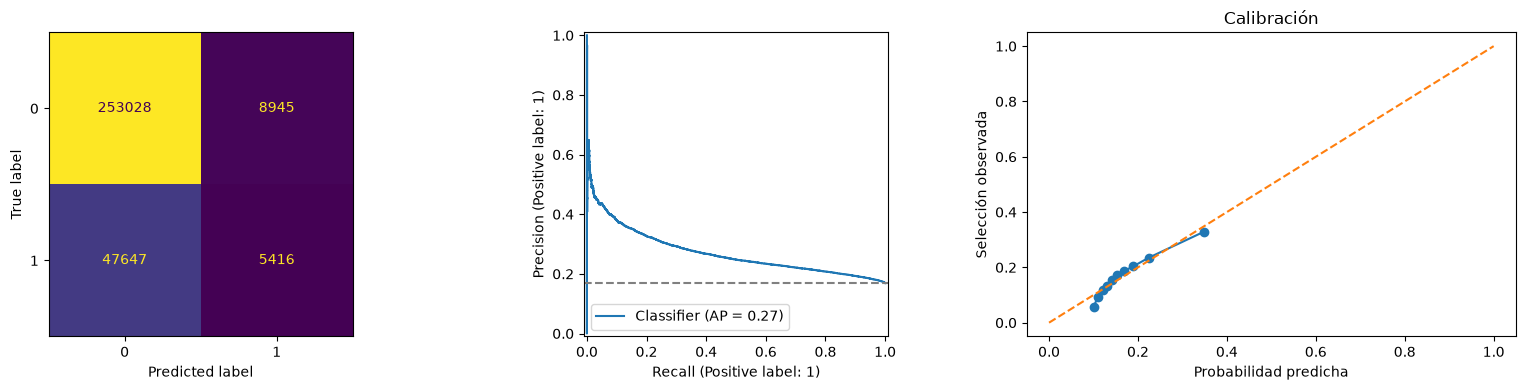

Precisión en test: 37.71%
Detección (recall) en test: 10.21%
Estas cifras corresponden al mismo histórico ya explorado, no a licitaciones futuras.


In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
y_test = y.iloc[partes["test"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, p_test >= artefacto["umbral"], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", color="gray")
cal = pd.DataFrame(informe["calibracion"])
axes[2].plot(cal.predicha, cal.observada, marker="o")
axes[2].plot([0,1], [0,1], linestyle="--")
axes[2].set(xlabel="Probabilidad predicha", ylabel="Selección observada", title="Calibración")
fig.tight_layout()
plt.show()

# El punto elegido hace visible la precisión y el recall del umbral fijado.
print(f"Precisión en test: {informe['test']['precision']:.2%}")
print(f"Detección (recall) en test: {informe['test']['recall']:.2%}")
print("Estas cifras corresponden al mismo histórico ya explorado, no a licitaciones futuras.")


## 2.6. Comparar deteccion minima del 30% y del 50%

Usamos el MLP ya entrenado, sin cambiar sus pesos: asi aislamos el efecto del umbral.
Los puntos se eligen exclusivamente con VALIDACION. Se muestran tambien el 10% y
el umbral F1 como referencias. Elegimos de antemano 30% como politica operativa
intermedia; 50% queda como alternativa para mayor cobertura. No se elige con test.

La precision puede bajar al recuperar mas ofertas seleccionadas. El minimo se exige
en validacion, no es una garantia en datos nuevos. El periodo historico ya se
examino antes y esta evaluacion sigue siendo exploratoria.


,politica,umbral,precision_validacion,recall_validacion,alertas_validacion
0,Deteccion minima 10%,0.326651,0.379078,0.100009,14100
1,Deteccion minima 30%,0.212756,0.294431,0.300028,54461
2,Deteccion minima 50%,0.171408,0.252938,0.500571,105769
3,Umbral F1,0.154084,0.235686,0.624717,141663


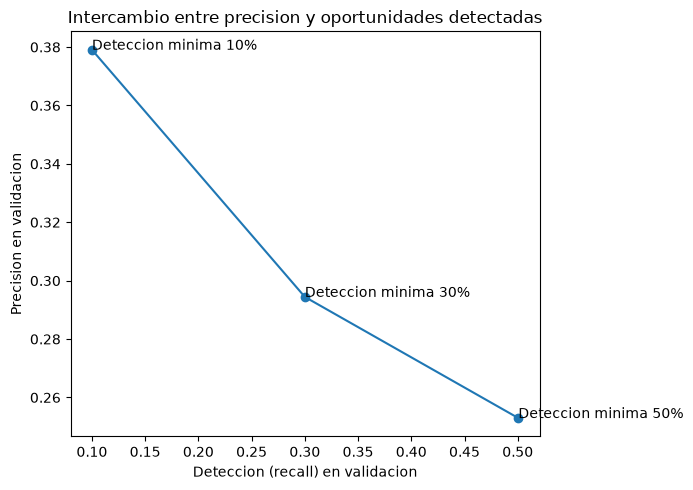

In [14]:
# Modifica este valor a 0.50 si prefieres la alternativa de mayor deteccion.
RECALL_OPERATIVO = 0.30
modelo_equilibrado = artefacto["modelo"]
val = partes["validacion"]
p_val_equilibrado = modelo_equilibrado.predict_proba(X.iloc[val])[:, 1]
comparacion_coberturas = []
umbrales_cobertura = {}
for cobertura in [0.10, 0.30, 0.50]:
    opt = umbral_precision(y.iloc[val], p_val_equilibrado, cobertura, MIN_ALERTAS_VALIDACION)
    umbrales_cobertura[cobertura] = opt["umbral"]
    comparacion_coberturas.append({
        "politica": f"Deteccion minima {cobertura:.0%}", "umbral": opt["umbral"],
        "precision_validacion": opt["precision_validacion"],
        "recall_validacion": opt["recall_validacion"],
        "alertas_validacion": opt["alertas_validacion"]})
t_f1 = umbral_f1(y.iloc[val], p_val_equilibrado)
m_f1 = metricas(y.iloc[val], p_val_equilibrado, t_f1)
comparacion_coberturas.append({
    "politica": "Umbral F1", "umbral": t_f1, "precision_validacion": m_f1["precision"],
    "recall_validacion": m_f1["recall"],
    "alertas_validacion": int((p_val_equilibrado >= t_f1).sum())})
tabla_coberturas = pd.DataFrame(comparacion_coberturas)
display(tabla_coberturas)
assert RECALL_OPERATIVO in umbrales_cobertura, "Elige 0.10, 0.30 o 0.50."

# Se fija el punto operativo antes de consultar las etiquetas de TEST.
umbral_operativo = umbrales_cobertura[RECALL_OPERATIVO]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(tabla_coberturas["recall_validacion"][:3],
        tabla_coberturas["precision_validacion"][:3], marker="o")
for _, fila in tabla_coberturas.iloc[:3].iterrows():
    ax.annotate(fila["politica"], (fila["recall_validacion"], fila["precision_validacion"]))
ax.set(xlabel="Deteccion (recall) en validacion", ylabel="Precision en validacion",
       title="Intercambio entre precision y oportunidades detectadas")
fig.tight_layout()
plt.show()


## 2.7. Evaluar solo el punto operativo elegido

El minimo del 30% se fijo como opcion intermedia antes de mirar esta prueba.
El modelo y sus probabilidades no cambian; cambia la regla para marcar un caso.
Se guarda un artefacto separado para que el notebook 03 utilice esta politica,
manteniendo disponible la referencia mas restrictiva del 10%.


In [15]:
import copy
test_equilibrado = partes["test"]
prob_equilibrado = modelo_equilibrado.predict_proba(X.iloc[test_equilibrado])[:, 1]
metricas_equilibradas = metricas(y.iloc[test_equilibrado], prob_equilibrado, umbral_operativo)
artefacto_equilibrado = dict(artefacto)
artefacto_equilibrado["umbral"] = float(umbral_operativo)
artefacto_equilibrado["informe"] = copy.deepcopy(artefacto["informe"])
ie = artefacto_equilibrado["informe"]
ie["test"] = metricas_equilibradas
ie["umbral"] = float(umbral_operativo)
ie["recall_minimo_validacion"] = RECALL_OPERATIVO
ie["politica"] = "Mayor precision con deteccion minima intermedia"
ie["comparacion_coberturas_validacion"] = tabla_coberturas.to_dict(orient="records")
ie["referencia_10_test"] = artefacto["informe"]["test"]
ie["positivos_predichos_test"] = int((prob_equilibrado >= umbral_operativo).sum())
ie["cobertura_test"] = float((prob_equilibrado >= umbral_operativo).mean())
joblib.dump(artefacto_equilibrado, SALIDA / "modelo_cobertura_equilibrada.joblib")
print("Punto operativo elegido: deteccion minima en validacion", RECALL_OPERATIVO)
display(pd.DataFrame({"Referencia restrictiva 10%": artefacto["informe"]["test"],
                      "Punto operativo intermedio": metricas_equilibradas})
        .drop(index="matriz_confusion_orden_0_1"))
print("Registros marcados en test:", ie["positivos_predichos_test"])
print("Proporcion marcada:", ie["cobertura_test"])


Punto operativo elegido: deteccion minima en validacion 0.3


,Referencia restrictiva 10%,Punto operativo intermedio
F1,0.160655,0.296303
precision,0.377133,0.292283
recall,0.102067,0.300435
ROC_AUC,0.646633,0.646633
average_precision,0.27129,0.27129
Brier,0.134782,0.134782
log_loss,0.435428,0.435428


Registros marcados en test: 54543
Proporcion marcada: 0.17313259437016723
